In [ ]:
!pip install -q qiskit qiskit-aer qiskit-ibm-runtime matplotlib pylatexenc

Crearemos nuestro circuito base

In [5]:
from qiskit import QuantumCircuit

num_qubits = 5

qc = QuantumCircuit(num_qubits, num_qubits)

# Superposition of 0 qubit
qc.h(0)
for i in range(1, num_qubits):
    qc.cx(i-1,i)

# Measure all
qc.measure_all(add_bits=False)

Y podremos visualizarlo

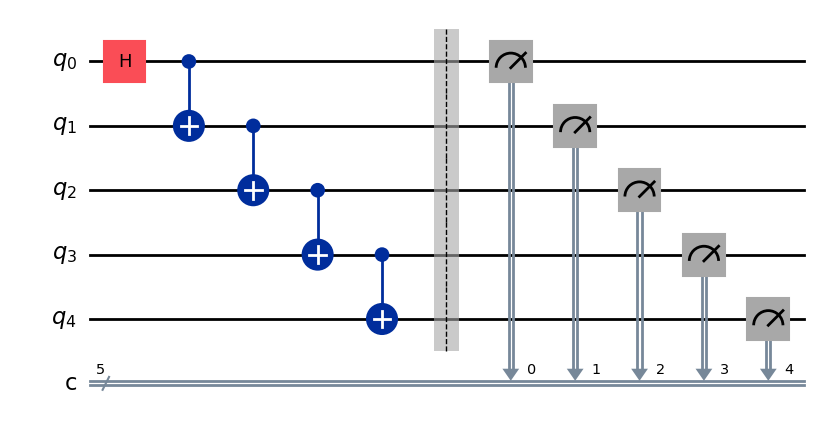

In [6]:
qc.draw('mpl')

Qiskit nos ofrece también la posibilidad de simular estos circuitos.

In [7]:
from qiskit_aer import AerSimulator

# execute the quantum circuit
simulator = AerSimulator()

result = simulator.run(qc, shots=1000).result()
counts  = result.get_counts(qc)
print(counts)

{'00000': 477, '11111': 523}


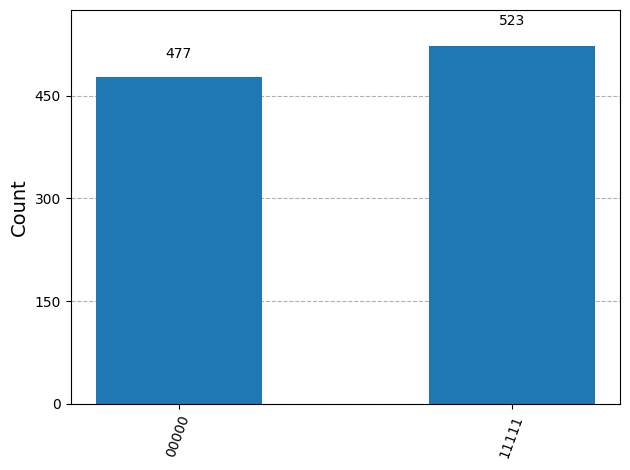

In [8]:
from qiskit.visualization import plot_histogram

plot_histogram(counts)

Lo interesante sucede cuando lo enviamos a nuestra instancia, a una de esas máquinas cuánticas disponibles.

In [9]:
from getpass import getpass

qiskit_api_key = getpass("Vuestra API de IBM")

In [12]:
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(
    token=qiskit_api_key, # Vuestro secreto
    set_as_default=False, # Optionally set these as your default credentials.
)

In [16]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

print("Sistemas disponibles:")
for backend in service.backends():
    print(backend.name)

qiskit_runtime_service.__init__:WARNING:2026-11-12 16:47:03,829: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-12 16:47:03,830: Loading instance: open-instance, plan: open


Sistemas disponibles:
ibm_fez
ibm_kingston
ibm_marrakesh


In [17]:
backend = service.backend("ibm_fez")
backend.status()

qiskit_runtime_service.backends:WARNING:2026-11-12 16:47:24,813: Using instance: open-instance, plan: open


Podemos ver qué pinta tiene ese chip. Cuantos cubits tiene, que tasa de error manejan, etc...

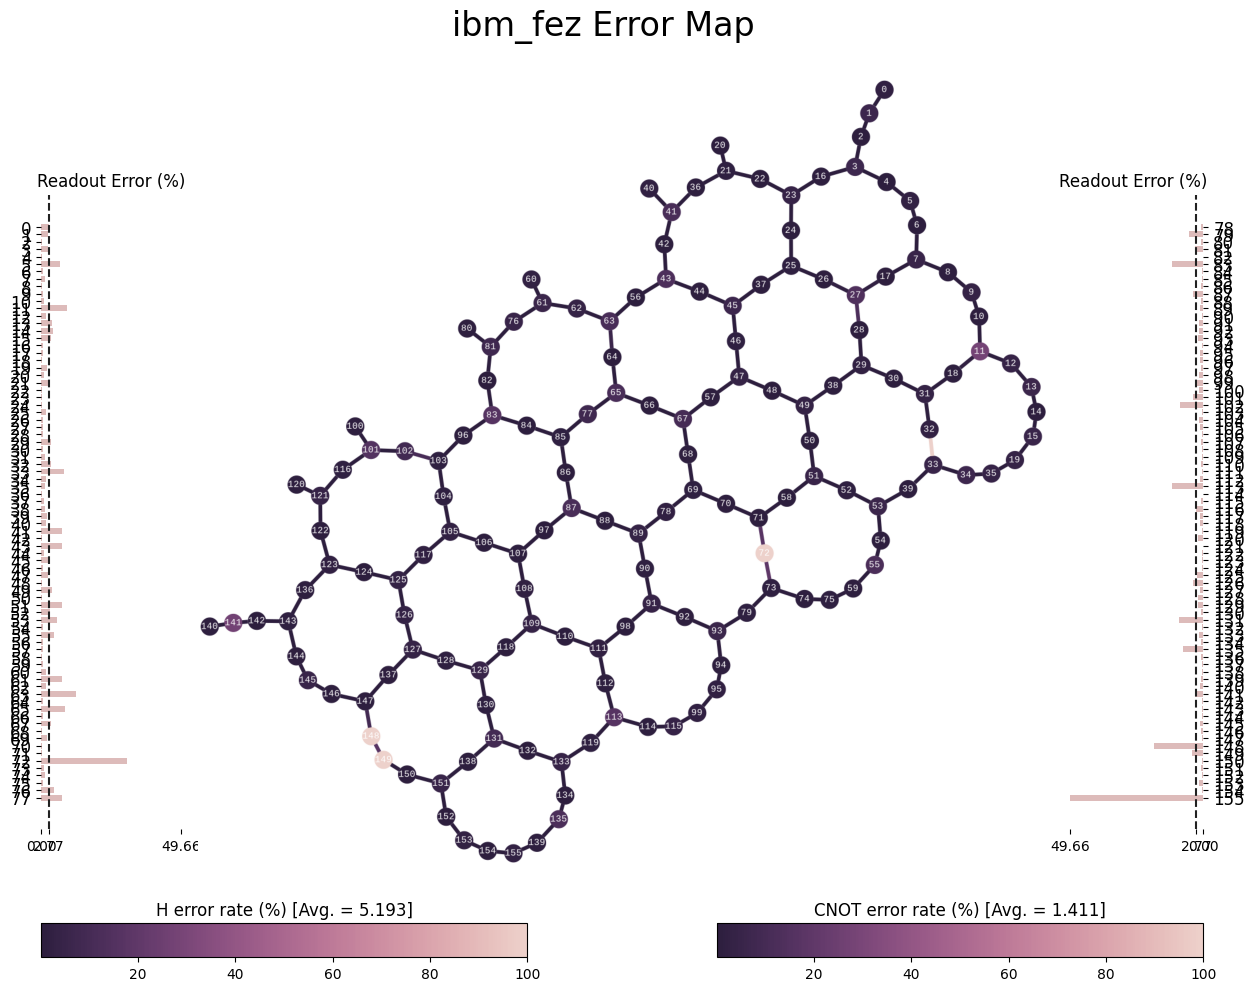

In [18]:
from qiskit import visualization

visualization.plot_error_map(backend)

Algo habitual antes de enviar nuestros programas es traducirlos a aquello que el hardware puede ejecutar:

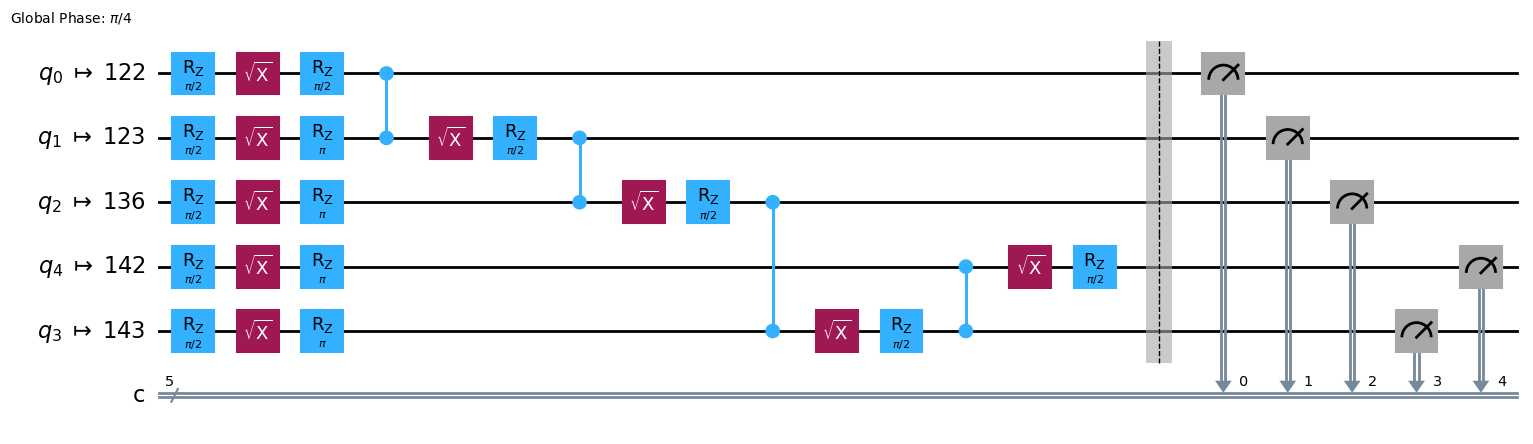

In [19]:
from qiskit import transpile

isa_circuit = transpile(qc, backend=backend)
isa_circuit.draw('mpl', idle_wires=False, fold=-1)

Y con eso podemos tomar muestras del estado que hayamos generado:

In [20]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

# Define Sampler
sampler = Sampler(mode=backend)
 
# Run calculation
job = sampler.run([isa_circuit])

print(f"This is your job id {job.job_id()}")

qiskit_runtime_service.backends:WARNING:2026-11-12 16:49:35,261: Using instance: open-instance, plan: open


This is your job id dbqus81abdes73fovqfg


Veréis el trabajo ejecutándose y cuando haya acabado obtener los resultados.

In [21]:
job.status()

'DONE'

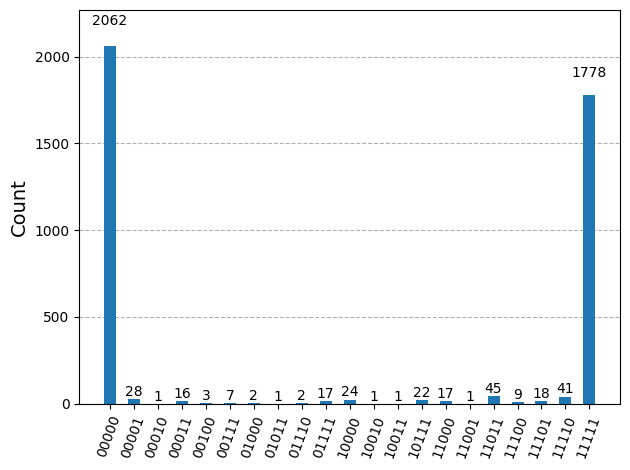

In [ ]:
from qiskit.visualization import plot_histogram

result = job.result()
counts = result[0].data.c.get_counts() # Este punto cambia en base a la versión de qiskit
plot_histogram(counts)

No es perfecto, pero tampoco está mal. ¿En algún momento os salen más 11111 que 00000? A mí tampoco.